# Forest Fire Detection — Part 2: Model and Training

Builds and trains **FireNet-CNN** (a CNN written from scratch) and tests two key hyperparameters. The trained model is saved for `03_evaluation.ipynb`.

## 0. Data Preparation

Same code as `01_preprocessing.ipynb` (sorted file order, `random_state=42`), so all notebooks use the **identical train / validation / test split**. The test images are never seen during training.

In [31]:
!pip install -q kaggle scikit-learn seaborn

import os
import shutil
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                              precision_score, recall_score, f1_score,
                              roc_curve, auc, accuracy_score)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))
tf.random.set_seed(42)
np.random.seed(42)

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [32]:
# Download the FIRE Dataset
!kaggle datasets download -d phylake1337/fire-dataset -p /content/data --unzip

DATA_DIR = "/content/data/fire_dataset"
print(os.listdir(DATA_DIR))

Dataset URL: https://www.kaggle.com/datasets/phylake1337/fire-dataset
License(s): CC0-1.0
100% 387M/387M [00:22<00:00, 17.9MB/s]

['fire_images', 'non_fire_images']


In [33]:
fire_dir = os.path.join(DATA_DIR, "fire_images")
non_fire_dir = os.path.join(DATA_DIR, "non_fire_images")

In [34]:
IMG_SIZE = 128

def load_images(folder, label, img_size=IMG_SIZE):
    images, labels = [], []
    for fname in sorted(os.listdir(folder)):
        if not fname.lower().endswith(('.png', '.jpg', '.jpeg')):
            continue
        path = os.path.join(folder, fname)
        try:
            img = tf.keras.utils.load_img(path, target_size=(img_size, img_size))
            img_array = tf.keras.utils.img_to_array(img) / 255.0   # normalize 0-1
            images.append(img_array)
            labels.append(label)
        except Exception as e:
            print(f"Skipping corrupt file: {fname} ({e})")
    return images, labels

print("Loading fire images...")
fire_imgs, fire_labels = load_images(fire_dir, label=1)

print("Loading non-fire images...")
non_fire_imgs, non_fire_labels = load_images(non_fire_dir, label=0)

X = np.array(fire_imgs + non_fire_imgs, dtype=np.float32)
y = np.array(fire_labels + non_fire_labels, dtype=np.float32)

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

Loading fire images...
Loading non-fire images...
X shape: (999, 128, 128, 3)
y shape: (999,)


In [35]:
# Split: 70% train, 15% val, 15% test  (stratified to preserve class balance)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Train: {X_train.shape[0]} images  ({y_train.sum():.0f} fire / {(y_train==0).sum():.0f} non-fire)")
print(f"Val:   {X_val.shape[0]} images  ({y_val.sum():.0f} fire / {(y_val==0).sum():.0f} non-fire)")
print(f"Test:  {X_test.shape[0]} images  ({y_test.sum():.0f} fire / {(y_test==0).sum():.0f} non-fire)")

Train: 699 images  (528 fire / 171 non-fire)
Val:   150 images  (114 fire / 36 non-fire)
Test:  150 images  (113 fire / 37 non-fire)


In [36]:
train_datagen = ImageDataGenerator(
    horizontal_flip=True,
    rotation_range=20,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1
)

# No augmentation for validation/test — only real, unmodified images are evaluated
val_datagen = ImageDataGenerator()
test_datagen = ImageDataGenerator()

BATCH_SIZE = 32

train_generator = train_datagen.flow(X_train, y_train, batch_size=BATCH_SIZE, shuffle=True)
val_generator = val_datagen.flow(X_val, y_val, batch_size=BATCH_SIZE, shuffle=False)
test_generator = test_datagen.flow(X_test, y_test, batch_size=BATCH_SIZE, shuffle=False)

## 1. Model Architecture

| Layer(s) | Purpose |
|---|---|
| 4 × (Conv2D 3×3 + MaxPool 2×2), filters 32 → 64 → 128 → 128 | Learn patterns (edges → textures → flame shapes); image shrinks 128 → 8 |
| Flatten | 8 × 8 × 128 → 8,192 values |
| Dropout 0.5 | Reduces overfitting |
| Dense 128 (ReLU) | Combines features |
| Dense 1 (Sigmoid) | Fire probability (0–1) |

In [37]:
def build_firenet_cnn(input_shape=(128, 128, 3)):
    model = models.Sequential(name="FireNet-CNN")

    # Block 1
    model.add(layers.Input(shape=input_shape))
    model.add(layers.Conv2D(32, (3, 3), activation='relu', padding='same'))
    model.add(layers.MaxPooling2D((2, 2)))

    # Block 2
    model.add(layers.Conv2D(64, (3, 3), activation='relu', padding='same'))
    model.add(layers.MaxPooling2D((2, 2)))

    # Block 3
    model.add(layers.Conv2D(128, (3, 3), activation='relu', padding='same'))
    model.add(layers.MaxPooling2D((2, 2)))

    # Block 4
    model.add(layers.Conv2D(128, (3, 3), activation='relu', padding='same'))
    model.add(layers.MaxPooling2D((2, 2)))

    # Classifier head
    model.add(layers.Flatten())
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(128, activation='relu'))
    model.add(layers.Dense(1, activation='sigmoid'))

    return model

model = build_firenet_cnn()
model.summary()

Model: "FireNet-CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,289,665 (4.92 MB)

 Trainable params: 1,289,665 (4.92 MB)

 Non-trainable params: 0 (0.00 B)

**1,289,665 parameters**, matching the report. Over 80% sit in the first Dense layer: (8,192 + 1) × 128 = 1,048,704.

In [38]:
# Verify parameter count matches the report (1,289,665)
total_params = model.count_params()
print(f"Total trainable parameters: {total_params:,}")

Total trainable parameters: 1,289,665


## 2. Compile

- **Adam**, learning rate **0.001**
- **Binary cross-entropy** loss (two classes, sigmoid output)
- Tracks accuracy, precision and **recall** (most important: a missed fire is the costliest error)

In [39]:
model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall')]
)

## 3. Class Weights and Callbacks

- **Class weights:** fire images outnumber non-fire about 3 : 1, so non-fire mistakes are weighted more (≈ **2.04** vs **0.66**).
- **EarlyStopping:** stops after 6 epochs without validation-loss improvement and restores the best weights.
- **ModelCheckpoint:** saves the best model during training.

In [40]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights))
print("Class weights:", class_weight_dict)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=6,
    restore_best_weights=True,
    verbose=1
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    '/content/firenet_cnn_best.keras',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

Class weights: {0: np.float64(2.043859649122807), 1: np.float64(0.6619318181818182)}


## 4. Training

Up to 30 epochs on augmented training images; validation checked every epoch.

In [41]:
EPOCHS = 30

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    class_weight=class_weight_dict,
    callbacks=[early_stop, checkpoint],
    verbose=1
)

Epoch 1/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 295ms/step - accuracy: 0.7710 - loss: 0.5859 - precision: 0.8680 - recall: 0.8267
Epoch 1: val_loss improved from None to 0.36457, saving model to /content/firenet_cnn_best.keras

Epoch 1: finished saving model to /content/firenet_cnn_best.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 12s 365ms/step - accuracy: 0.8426 - loss: 0.4502 - precision: 0.9197 - recall: 0.8674 - val_accuracy: 0.8200 - val_loss: 0.3646 - val_precision: 1.0000 - val_recall: 0.7632
Epoch 2/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.9369 - loss: 0.1897 - precision: 0.9711 - recall: 0.9455
Epoch 2: val_loss did not improve from 0.36457
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 145ms/step - accuracy: 0.9356 - loss: 0.2027 - precision: 0.9708 - recall: 0.9432 - val_accuracy: 0.7667 - val_loss: 0.8560 - val_precision: 1.0000 - val_recall: 0.6930
Epoch 3/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: 0.8835 - loss: 0.2667 - precision: 0.9746 - recall: 0.8611
Epoch 3: val_loss imp

**Result:** stopped at epoch **9**; best weights from epoch **3** (val loss 0.119, val recall 0.956) restored.

## 5. Training Curves

- Train and validation curves moving together → model is generalising.
- Validation rising/falling while training keeps improving → overfitting.

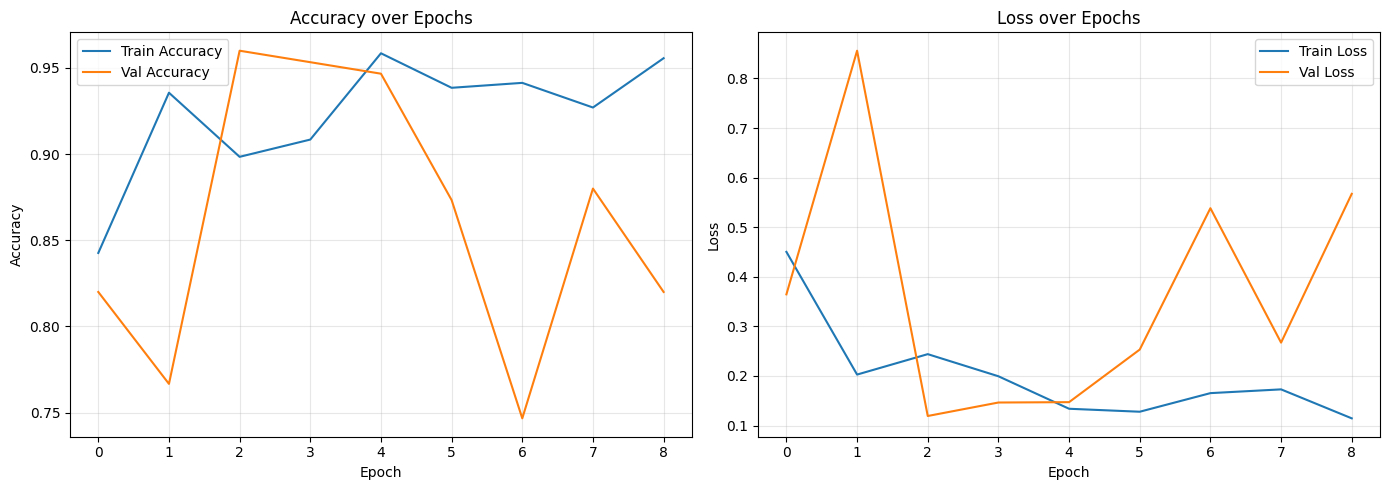

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['accuracy'], label='Train Accuracy')
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy')
axes[0].set_title('Accuracy over Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history.history['loss'], label='Train Loss')
axes[1].plot(history.history['val_loss'], label='Val Loss')
axes[1].set_title('Loss over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Per-metric view: loss, accuracy, precision, recall.

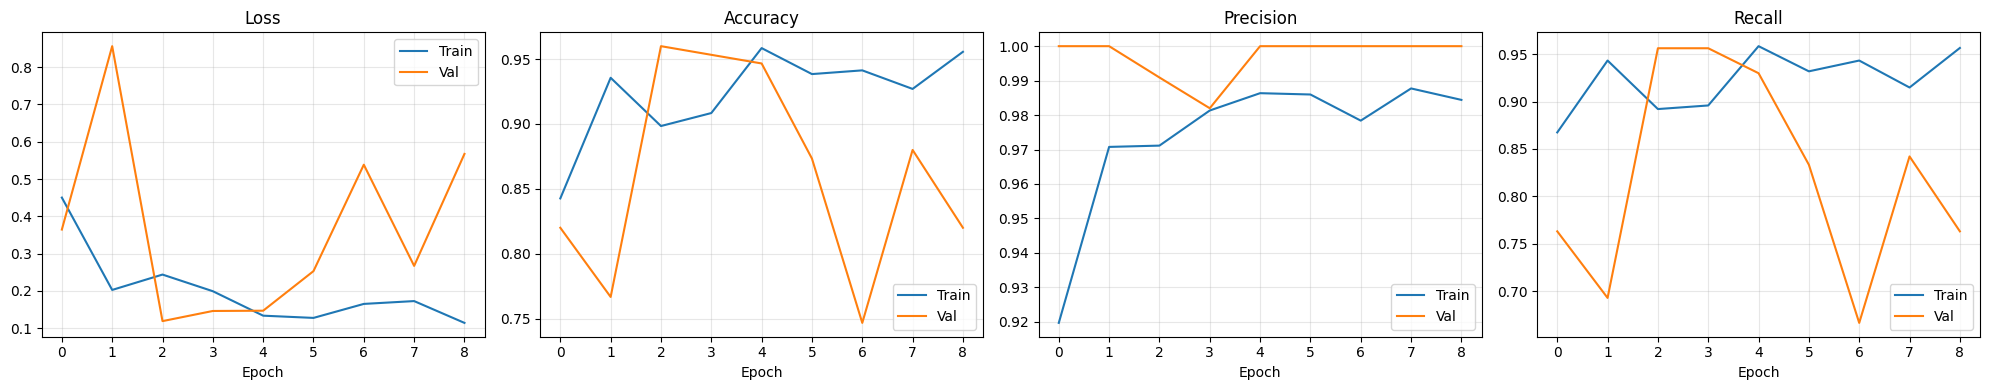

In [43]:
metrics_to_plot = ['loss', 'accuracy', 'precision', 'recall']
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, m in zip(axes, metrics_to_plot):
    ax.plot(history.history[m], label='Train')
    ax.plot(history.history[f'val_{m}'], label='Val')
    ax.set_title(m.capitalize()); ax.set_xlabel('Epoch')
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Analysis**
- Training loss falls steadily → the model is learning.
- Validation loss is lowest at epoch 3, then rises → overfitting starts; early stopping kept the epoch-3 model.
- Validation swings are due to the small validation set (150 images).

## 6. Hyperparameter Experiment

Same model trained with **learning rate ∈ {0.001, 0.0001}** × **dropout ∈ {0.3, 0.5}** (4 runs). Everything else is unchanged. Compared on the **validation set only**.


=== Training: lr=0.001, dropout=0.5 ===
{'Learning rate': 0.001, 'Dropout': 0.5, 'Epochs run': 15, 'Best epoch': 9, 'Val loss': 0.1022, 'Val accuracy': 0.96, 'Val precision': 0.9909, 'Val recall': 0.9561, 'Val F1': 0.9732}

=== Training: lr=0.001, dropout=0.3 ===
{'Learning rate': 0.001, 'Dropout': 0.3, 'Epochs run': 8, 'Best epoch': 2, 'Val loss': 0.1284, 'Val accuracy': 0.9533, 'Val precision': 0.9573, 'Val recall': 0.9825, 'Val F1': 0.9697}

=== Training: lr=0.0001, dropout=0.5 ===
{'Learning rate': 0.0001, 'Dropout': 0.5, 'Epochs run': 11, 'Best epoch': 5, 'Val loss': 0.1813, 'Val accuracy': 0.9133, 'Val precision': 0.981, 'Val recall': 0.9035, 'Val F1': 0.9406}

=== Training: lr=0.0001, dropout=0.3 ===
{'Learning rate': 0.0001, 'Dropout': 0.3, 'Epochs run': 14, 'Best epoch': 8, 'Val loss': 0.1612, 'Val accuracy': 0.94, 'Val precision': 1.0, 'Val recall': 0.9211, 'Val F1': 0.9589}

Results (sorted by validation recall, our main metric):


,Learning rate,Dropout,Epochs run,Best epoch,Val loss,Val accuracy,Val precision,Val recall,Val F1
1,0.0010,0.3,8,2,0.1284,0.9533,0.9573,0.9825,0.9697
0,0.0010,0.5,15,9,0.1022,0.9600,0.9909,0.9561,0.9732
3,0.0001,0.3,14,8,0.1612,0.9400,1.0000,0.9211,0.9589
2,0.0001,0.5,11,5,0.1813,0.9133,0.9810,0.9035,0.9406


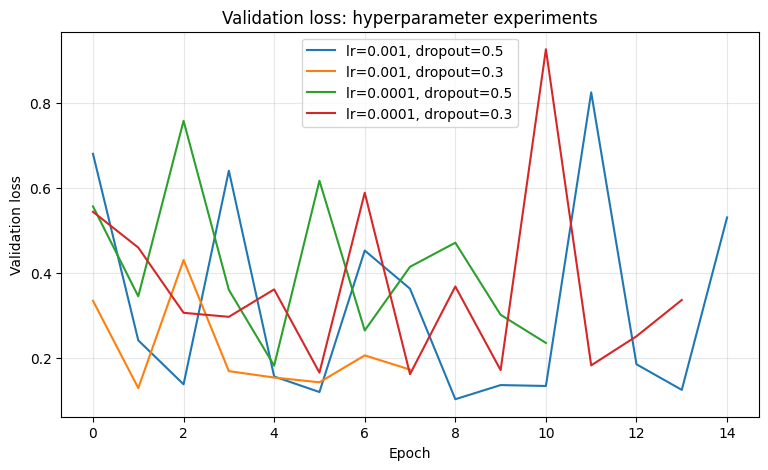

In [29]:
# Train the same model with 4 learning-rate / dropout combinations and compare them
import pandas as pd

def build_variant(dropout_rate, input_shape=(128, 128, 3)):
    """Same FireNet-CNN as above, but with a configurable dropout rate."""
    m = models.Sequential(name=f"FireNet-dropout{dropout_rate}")
    m.add(layers.Input(shape=input_shape))
    for filters in [32, 64, 128, 128]:
        m.add(layers.Conv2D(filters, (3, 3), activation='relu', padding='same'))
        m.add(layers.MaxPooling2D((2, 2)))
    m.add(layers.Flatten())
    m.add(layers.Dropout(dropout_rate))
    m.add(layers.Dense(128, activation='relu'))
    m.add(layers.Dense(1, activation='sigmoid'))
    return m

experiments = [
    {"lr": 1e-3, "dropout": 0.5},   # our main model's settings
    {"lr": 1e-3, "dropout": 0.3},
    {"lr": 1e-4, "dropout": 0.5},
    {"lr": 1e-4, "dropout": 0.3},
]

results = []
all_histories = {}

for cfg in experiments:
    tf.keras.backend.clear_session()
    tf.random.set_seed(42)
    np.random.seed(42)

    m = build_variant(cfg["dropout"])
    m.compile(
        optimizer=optimizers.Adam(learning_rate=cfg["lr"]),
        loss='binary_crossentropy',
        metrics=['accuracy',
                 tf.keras.metrics.Precision(name='precision'),
                 tf.keras.metrics.Recall(name='recall')]
    )
    stop = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=6, restore_best_weights=True)

    name = f"lr={cfg['lr']:g}, dropout={cfg['dropout']}"
    print(f"\n=== Training: {name} ===")
    h = m.fit(train_generator, validation_data=val_generator,
              epochs=30, class_weight=class_weight_dict,
              callbacks=[stop], verbose=0)
    all_histories[name] = h.history

    # Score the restored best weights on the VALIDATION set
    # (the test set stays untouched for the final model only)
    val_probs = m.predict(X_val, verbose=0).ravel()
    val_pred = (val_probs >= 0.5).astype(int)
    y_val_int = y_val.astype(int)
    best_epoch = int(np.argmin(h.history['val_loss'])) + 1

    results.append({
        "Learning rate": cfg["lr"],
        "Dropout": cfg["dropout"],
        "Epochs run": len(h.history['loss']),
        "Best epoch": best_epoch,
        "Val loss": round(min(h.history['val_loss']), 4),
        "Val accuracy": round(accuracy_score(y_val_int, val_pred), 4),
        "Val precision": round(precision_score(y_val_int, val_pred), 4),
        "Val recall": round(recall_score(y_val_int, val_pred), 4),
        "Val F1": round(f1_score(y_val_int, val_pred), 4),
    })
    print(results[-1])

results_df = pd.DataFrame(results).sort_values("Val recall", ascending=False)
print("\nResults (sorted by validation recall, our main metric):")
display(results_df)

# Validation loss curves for all 4 runs on one chart
plt.figure(figsize=(9, 5))
for name, hist in all_histories.items():
    plt.plot(hist['val_loss'], label=name)
plt.title('Validation loss: hyperparameter experiments')
plt.xlabel('Epoch')
plt.ylabel('Validation loss')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Analysis**
- **Learning rate 0.001 is clearly better** than 0.0001 (lower loss, higher recall with both dropouts).
- **Dropout makes little difference** (≈ 3 images out of 114); 0.5 gives the lowest loss and best F1, so it is kept.

## 7. Save the Model

Saves `firenet_cnn_final.keras` (best weights) for `03_evaluation.ipynb`.

In [30]:
model.save('/content/firenet_cnn_final.keras')
print("Model saved to /content/firenet_cnn_final.keras")

# Download the model file so it can be shared with Part 3
from google.colab import files
files.download('/content/firenet_cnn_final.keras')

Model saved to /content/firenet_cnn_final.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>